# **Proyecto final**

# Resumen: Extracción de Características y Manejo de Deformaciones en ECG

## 1) Extracción de Características (*Feature Extraction*)

En el estudio de Zheng et al. (2020), la extracción de características se diseñó para superar las limitaciones de los métodos tradicionales y de las redes neuronales profundas. Los enfoques tradicionales dependen de la detección rígida de picos e intervalos en las componentes principales del latido (onda P, complejo QRS y onda T), lo cual falla en presencia de distorsiones o ausencias de ondas. Por otro lado, las redes neuronales profundas actúan como "cajas negras" ininterpretables con alto costo computacional, mientras que la FFT o la Transformada Wavelet pierden la información en el dominio del tiempo.

El método propuesto introduce una estrategia **interpretable, robusta y basada en distribuciones de frecuencia empírica**:

* **Preprocesamiento y Escalado de Amplitud**: 
  Las señales de ECG de 10 segundos (muestreadas a 500 Hz) se reescalan mediante un algoritmo de máximo-mínimo para unificar la escala de amplitud a un pico máximo de 1.

* **Datos Clínicos y Parámetros Básicos de la Máquina**: 
  Se incluyen la **edad y el género** del paciente, junto con 11 características básicas proporcionadas por la máquina de ECG (ritmo ventricular, ritmo auricular, duración del QRS, intervalo QT, ejes de R y T, conteo de QRS, inicio de Q y fin de Q). En la derivación II se calculan además el promedio, la varianza y el conteo de los intervalos RR.

* **Agrupación Flexible de Picos y Valles**: 
  En lugar de identificar rígida y explícitamente ondas específicas, las deflexiones (máximos y mínimos locales) se clasifican en **tres subconjuntos**:
  1. **Complejo QRS**
  2. **Picos no-QRS**
  3. **Valles**
  
  Para cada elemento se evalúan tres atributos morfológicos: **altura**, **ancho** y **prominencia** (distancia vertical entre la cúspide y su línea de contorno inferior más baja).

* **Relaciones por Pares y Razones Temporales**: 
  Se analizan las interacciones entre los componentes sobre **6 combinaciones por pares** (QRS vs QRS, no-QRS vs no-QRS, valles vs valles, QRS vs no-QRS, QRS vs valles, no-QRS vs valles). Para cada par, se calculan tres razones relativas a la diferencia temporal:
  $$\text{Razón de Altura} = \frac{\Delta \text{Altura}}{\Delta \text{Tiempo}}, \quad \text{Razón de Ancho} = \frac{\Delta \text{Ancho}}{\Delta \text{Tiempo}}, \quad \text{Razón de Prominencia} = \frac{\Delta \text{Prominencia}}{\Delta \text{Tiempo}}$$

* **Tablas de Distribución de Frecuencia Empírica**: 
  Dado que cada paciente presenta un número variable de picos y valles según su ritmo o condición médica, las razones no pueden ingresarse directamente como vectores de entrada. Los autores construyen **tablas de frecuencia empírica de 100 intervalos (bins)** entre los valores máximo y mínimo de cada atributo y razón. Esto genera vectores de características de longitud uniforme (desde 11 en el Grupo 1 hasta 39,830 en el Grupo 11 para 12 derivaciones).

---

## 1.1) Discusión: Manejo de la Desaparición o Distorsión de Ondas en el Complejo PQRS

En diversas arritmias y patologías cardíacas, las deflexiones habituales (como la onda P o fragmentos del complejo QRS) pueden distorsionarse severamente o **desaparecer por completo**.

* **Limitación de los Algoritmos Convencionales**: 
  En patologías como la **fibrilación auricular (AFIB)** o el **aleteo auricular (AFL)**, la onda P desaparece y es reemplazada por múltiples ondas de fibrilación/aleteo de baja amplitud que no están sincronizadas con el complejo QRS. Asimismo, condiciones como las contracciones ventriculares prematuras (PVC), contracciones auriculares prematuras (APC) o bloqueos de rama (RBBB, LBBB) deforman el complejo QRS. Los algoritmos basados en la búsqueda de picos específicos fallan en estos escenarios.

* **Solución Propuesta en el Artículo**:
  1. **Abstracción mediante Picos No-QRS y Valles**: Al clasificar cualquier deflexión secundaria como pico no-QRS o valle sin forzar la etiqueta de "onda P", el algoritmo procesa las múltiples ondas fibrilatorias dentro del grupo de picos no-QRS sin interrupciones ni fallos de segmentación.
  2. **Resumen Estadístico mediante Histogramas Empíricos**: Las modificaciones en la presencia, número o forma de las ondas quedan reflejadas cuantitativamente en la forma de las **distribuciones de frecuencia empírica (100 bins)** de alturas, anchos, prominencias y sus razones.
  3. **Preservación de la Información en el Dominio del Tiempo**: Al evaluar las razones de variación espacial divididas por la diferencia de tiempo ($\Delta \text{Magnitud} / \Delta \text{Tiempo}$), el modelo mantiene la relación temporal esencial entre ondas y segmentos, garantizando una alta precisión diagnóstica incluso ante ondas ausentes o distorsionadas.
```


## **Introducción**

### **2)** Se descarga la base de datos ECGData.zip  y se filtra. Seleccionar las mismas arritmias seleccionadas en el proyecto 1  

### - **Respuesta**
Se extraen los archivos con las correspondientes arritmias propias del Proyecto 1

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
import numpy as np
from scipy import stats
from scipy.signal import butter, filtfilt, welch
from statsmodels.nonparametric.smoothers_lowess import lowess
from sklearn.metrics import mean_squared_error



In [2]:
# Rutas RELATIVAS a la raíz del repositorio (iguales para todo el equipo).
# Busca la carpeta "data" subiendo desde donde se abra el notebook.
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "data").exists())
DATA_DIR = ROOT / "data"
DIAGNOSTICS_PATH = DATA_DIR / "Diagnostics.xlsx"
SIGNALS_DIR = DATA_DIR / "ECGData"

FS = 500                       # Hz
LEADS = ["I", "II", "III", "aVR", "aVL", "aVF", "V1", "V2", "V3", "V4", "V5", "V6"]
DERIVACION = "II"

diagnostics = pd.read_excel(DIAGNOSTICS_PATH)
diagnosis_column = diagnostics.columns[1]          # "Rhythm"

# Normalizar texto de las columnas categóricas (misma lógica que en la Parte 1)
diagnostics[diagnosis_column] = diagnostics[diagnosis_column].astype(str).str.strip().str.upper()
diagnostics["Gender"] = diagnostics["Gender"].astype(str).str.strip().str.upper()

print("Registros:", len(diagnostics))
print("Columnas:", list(diagnostics.columns))

Registros: 10646
Columnas: ['FileName', 'Rhythm', 'Beat', 'PatientAge', 'Gender', 'VentricularRate', 'AtrialRate', 'QRSDuration', 'QTInterval', 'QTCorrected', 'RAxis', 'TAxis', 'QRSCount', 'QOnset', 'QOffset', 'TOffset']


In [3]:
# ARRITMIA SB

sb_diagnostics = diagnostics[
    diagnostics[diagnosis_column]
    .astype(str)
    .str.strip()
    .str.upper()
    .eq("SB")
].copy()
#Esta parte filtra diagnostics y conserva únicamente las filas cuyo diagnóstico sea "SB"


FILENAME_SB = sb_diagnostics["FileName"].astype(str).tolist()
#De los registros que quedaron después del filtro, toma únicamente la columna FileName.
# .tolist() convierte esa columna en una lista de Python,
# por lo tanto, FILENAME_SB contiene los nombres de los archivos correspondientes a los registros diagnosticados como SB.


print(f"\nNúmero de pacientes/registros con SB: {len(FILENAME_SB)}")

#ARRITMIA SR

SR_diagnostics = diagnostics[
    diagnostics[diagnosis_column]
    .astype(str)
    .str.strip()
    .str.upper()
    .eq("SR")
].copy()

FILENAME_SR = SR_diagnostics["FileName"].astype(str).tolist()
print(f"\nNúmero de pacientes/registros con SR: {len(FILENAME_SR)}")

#ARRITMIA AFIB

AFIB_diagnostics = diagnostics[
    diagnostics[diagnosis_column]
    .astype(str)
    .str.strip()
    .str.upper()
    .eq("AFIB")
].copy()

FILENAME_AFIB = AFIB_diagnostics["FileName"].astype(str).tolist()
print(f"\nNúmero de pacientes/registros con AFIB: {len(FILENAME_AFIB)}")

#ARRITMIA ST

ST_diagnostics = diagnostics[
    diagnostics[diagnosis_column]
    .astype(str)
    .str.strip()
    .str.upper()
    .eq("ST")
].copy()

FILENAME_ST = ST_diagnostics["FileName"].astype(str).tolist()
print(f"\nNúmero de pacientes/registros con ST: {len(FILENAME_ST)}")

#ARRITMIA AF

AF_diagnostics = diagnostics[
    diagnostics[diagnosis_column]
    .astype(str)
    .str.strip()
    .str.upper()
    .eq("AF")
].copy()

FILENAME_AF = AF_diagnostics["FileName"].astype(str).tolist()
print(f"\nNúmero de pacientes/registros con AF: {len(FILENAME_AF)}")

#ARRITMIA SI

SA_diagnostics = diagnostics[
    diagnostics[diagnosis_column]
    .astype(str)
    .str.strip()
    .str.upper()
    .eq("SA")
].copy()
FILENAME_SA = SA_diagnostics["FileName"].astype(str).tolist()
print(f"\nNúmero de pacientes/registros con SA: {len(FILENAME_SA)}")

#ARRITMIA SVT

SVT_diagnostics = diagnostics[
    diagnostics[diagnosis_column]
    .astype(str)
    .str.strip()
    .str.upper()
    .eq("SVT")
].copy()

FILENAME_SVT = SVT_diagnostics["FileName"].astype(str).tolist()
print(f"\nNúmero de pacientes/registros con SVT: {len(FILENAME_SVT)}")

#ARRITMIA AT

AT_diagnostics = diagnostics[
    diagnostics[diagnosis_column]
    .astype(str)
    .str.strip()
    .str.upper()
    .eq("AT")
].copy()

FILENAME_AT = AT_diagnostics["FileName"].astype(str).tolist()
print(f"\nNúmero de pacientes/registros con AT: {len(FILENAME_AT)}")

#ARRITMIA AVNRT

AVNRT_diagnostics = diagnostics[
    diagnostics[diagnosis_column]
    .astype(str)
    .str.strip()
    .str.upper()
    .eq("AVNRT")
].copy()

FILENAME_AVNRT = AVNRT_diagnostics["FileName"].astype(str).tolist()
print(f"\nNúmero de pacientes/registros con AVNRT: {len(FILENAME_AVNRT)}")

#ARRITMIA AVRT

AVRT_diagnostics = diagnostics[
    diagnostics[diagnosis_column]
    .astype(str)
    .str.strip()
    .str.upper()
    .eq("AVRT")
].copy()

FILENAME_AVRT = AVRT_diagnostics["FileName"].astype(str).tolist()
print(f"\nNúmero de pacientes/registros con AVRT: {len(FILENAME_AVRT)}")

#ARRITMIA SAAWR

SAAWR_diagnostics = diagnostics[
    diagnostics[diagnosis_column]
    .astype(str)
    .str.strip()
    .str.upper()
    .eq("SAAWR")
].copy()

FILENAME_SAAWR = SAAWR_diagnostics["FileName"].astype(str).tolist()
print(f"\nNúmero de pacientes/registros con SAAWR: {len(FILENAME_SAAWR)}")


Número de pacientes/registros con SB: 3889

Número de pacientes/registros con SR: 1826

Número de pacientes/registros con AFIB: 1780

Número de pacientes/registros con ST: 1568

Número de pacientes/registros con AF: 445

Número de pacientes/registros con SA: 399

Número de pacientes/registros con SVT: 587

Número de pacientes/registros con AT: 121

Número de pacientes/registros con AVNRT: 16

Número de pacientes/registros con AVRT: 8

Número de pacientes/registros con SAAWR: 7


- Visualizamos la señal, por medio de la transformada rápida de Fourier y seguidamente la graficación de la señal para poder analizar los componentes frecuenciales de la señal 

Arritmia SB: 5000 muestras
Arritmia SR: 5000 muestras
Arritmia AFIB: 5000 muestras
Arritmia ST: 5000 muestras
Arritmia AF: 5000 muestras
Arritmia SA: 5000 muestras
Arritmia SVT: 5000 muestras
Arritmia AT: 5000 muestras
Arritmia AVNRT: 5000 muestras
Arritmia AVRT: 5000 muestras
Arritmia SAAWR: 5000 muestras


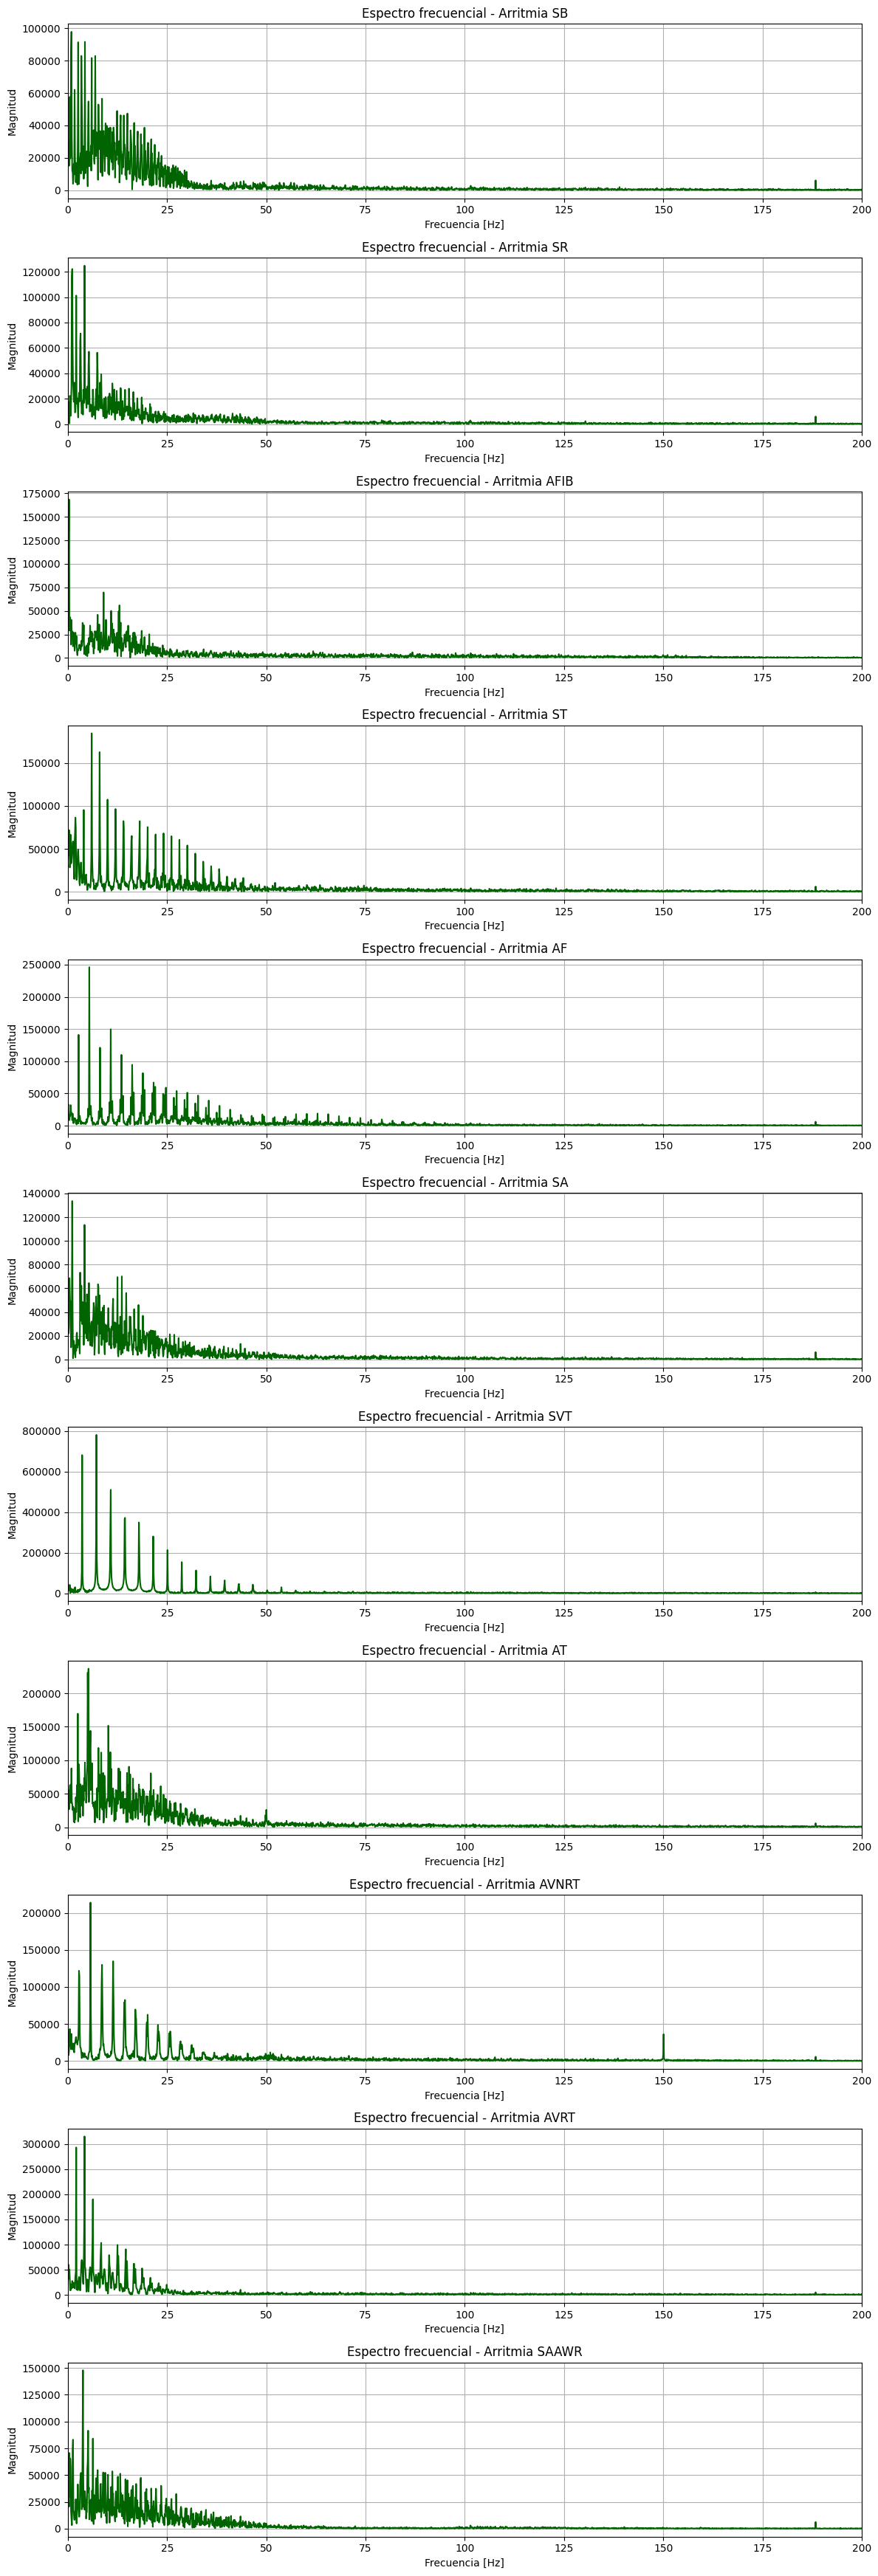

In [4]:
archivos = list(SIGNALS_DIR.iterdir())
# Seleccionar un archivo de ECGData
archivo = SIGNALS_DIR / archivos[0]

# Leer las primeras filas del CSV
datos = pd.read_csv(archivo, nrows=10)


# Se crea un diccionario que relaciona cada tipo de arritmia
# con la lista de archivos que contienen sus registros ECG.
arritmias = {
    "SB": FILENAME_SB,
    "SR": FILENAME_SR,
    "AFIB": FILENAME_AFIB,
    "ST": FILENAME_ST,
    "AF": FILENAME_AF,
    "SA": FILENAME_SA,
    "SVT": FILENAME_SVT,
    "AT": FILENAME_AT,
    "AVNRT": FILENAME_AVNRT,
    "AVRT": FILENAME_AVRT,
    "SAAWR": FILENAME_SAAWR
}


# ============================================================
# CREAR LA FIGURA PARA REPRESENTAR LOS ESPECTROS
# ============================================================

# Se crea una figura de 12 pulgadas de ancho y 35 de alto.
# Se utilizarán 11 gráficas, una para cada tipo de arritmia.
plt.figure(figsize=(12, 35))


# ============================================================
# RECORRER CADA TIPO DE ARRITMIA
# ============================================================

# Se recorren los elementos del diccionario.
# 'i' representa el índice de la iteración.
# 'nombre' contiene el nombre de la arritmia.
# 'archivos' contiene la lista de registros disponibles.
for i, (nombre, archivos) in enumerate(arritmias.items()):

    # Se verifica si la lista de archivos está vacía.
    # Si no existen registros para esa arritmia,
    # se muestra un mensaje y se continúa con la siguiente.
    if len(archivos) == 0:
        print(f"No hay registros para {nombre}")
        continue

    # Se selecciona únicamente el primer archivo de la lista
    # correspondiente a cada tipo de arritmia.
    archivo = archivos[0]

    # Se construye la ruta del archivo utilizando
    # el directorio donde se encuentran las señales ECG.
    ruta_archivo = SIGNALS_DIR / archivo

    # Se comprueba si el archivo existe en la ruta indicada.
    # Si no existe, se intenta localizar agregando la extensión .csv.
    if not ruta_archivo.exists():
        ruta_archivo = SIGNALS_DIR / f"{archivo}.csv"

    # Se carga el archivo CSV utilizando Pandas.
    # Los datos del registro ECG quedan almacenados en un DataFrame.
    datos = pd.read_csv(ruta_archivo)

    # Se extrae la columna correspondiente a la derivación
    # electrocardiográfica definida en la variable DERIVACION.
    # to_numpy() convierte los datos en un arreglo de NumPy
    # para facilitar el procesamiento matemático de la señal.
    signal = datos[DERIVACION].to_numpy()


    # ========================================================
    # TRANSFORMADA RÁPIDA DE FOURIER (FFT)
    # ========================================================

    # Se aplica la Transformada Rápida de Fourier (FFT)
    # a la señal ECG para convertirla del dominio del tiempo
    # al dominio de la frecuencia.
    signal_fft = np.fft.fft(signal)

    # Se obtiene la cantidad total de muestras de la señal
    # transformada, que corresponde a la cantidad de muestras
    # del registro ECG original.
    N = len(signal_fft)

    # Se imprime el nombre de la arritmia y la cantidad
    # de muestras utilizadas en el procesamiento.
    print(f"Arritmia {nombre}: {N} muestras")


    # ========================================================
    # CONSTRUIR EL VECTOR DE FRECUENCIAS
    # ========================================================

    # Se genera un vector con las frecuencias asociadas
    # a cada componente de la FFT.
    # FS corresponde a la frecuencia de muestreo de la señal.
    # N corresponde al número total de muestras.
    # La resolución frecuencial es FS/N.
    F = np.arange(0, N) * FS / N


    # ========================================================
    # EXTRAER LA PRIMERA MITAD DEL ESPECTRO
    # ========================================================

    # Se calcula la cantidad de elementos que corresponden
    # a la primera mitad del espectro de frecuencias.
    N_mitad = int(np.ceil(N / 2))

    # Se extrae la primera mitad del vector de frecuencias,
    # correspondiente a las frecuencias positivas.
    F_mitad = F[0:N_mitad]

    # Se extrae la primera mitad de los coeficientes
    # obtenidos mediante la Transformada de Fourier.
    # Esto evita representar la parte simétrica del espectro.
    signal_fft_mitad = signal_fft[0:N_mitad]


    # ========================================================
    # GRAFICAR EL ESPECTRO DE FRECUENCIAS
    # ========================================================

    # Se selecciona la posición de la gráfica dentro de la figura.
    # Se organizan 11 filas y 1 columna.
    # i + 1 indica la posición de la gráfica actual.
    plt.subplot(11, 1, i + 1)

    # Se representa el espectro frecuencial de la señal ECG.
    # En el eje X se ubican las frecuencias en Hz.
    # En el eje Y se representa la magnitud de los coeficientes
    # de Fourier mediante el valor absoluto de la FFT.
    plt.plot(
        F_mitad,
        np.abs(signal_fft_mitad),
        color='darkgreen'
    )

    # Se asigna un título que identifica el espectro
    # correspondiente al tipo de arritmia analizado.
    plt.title(f"Espectro frecuencial - Arritmia {nombre}")

    # Se etiqueta el eje horizontal con la frecuencia en Hz.
    plt.xlabel("Frecuencia [Hz]")

    # Se etiqueta el eje vertical con la magnitud del espectro.
    plt.ylabel("Magnitud")

    # Se limita la visualización del eje de frecuencias
    # al intervalo comprendido entre 0 y 200 Hz.
    plt.xlim(0, 200)

    # Se activa la cuadrícula para facilitar
    # la lectura e interpretación de los espectros.
    plt.grid(True)


# ============================================================
# AJUSTAR Y MOSTRAR LOS RESULTADOS
# ============================================================

# Se ajusta automáticamente la distribución de las gráficas
# para evitar superposición entre títulos y etiquetas.
plt.tight_layout()

# Se muestra la figura con los espectros frecuenciales
# correspondientes a los diferentes tipos de arritmias.
plt.show()


- En cada una de las arritmias se visualizan componentes frecuenciales propias de un ECG desde aproximadamente los 0 Hz, hasta los 40 - 50 Hz. Sin embargo, tambien se observa una alta componente de ruido presente en la señal, con picos sobresalientes alrededor de los 180 Hz, y los generados por el ruido electrico alrededor de los 60 Hz. 

### **3)**  Programar el flujo de filtrado explicado en el articulo y validar el resultado comparando señales de la base de datos del proyecto 1 con la misma señal con los filtros programados en este proyecto 2. Aplicar el filtrado a las señales

### - **Resultado**

Validación Registro MUSE_20180209_172046_21000 (Proyecto 1 vs Proyecto 2):
  - Correlación de Pearson (r): 0.9328
  - RMSE: 52.5846 µV | PRD: 50.17% | SNR: 5.99 dB


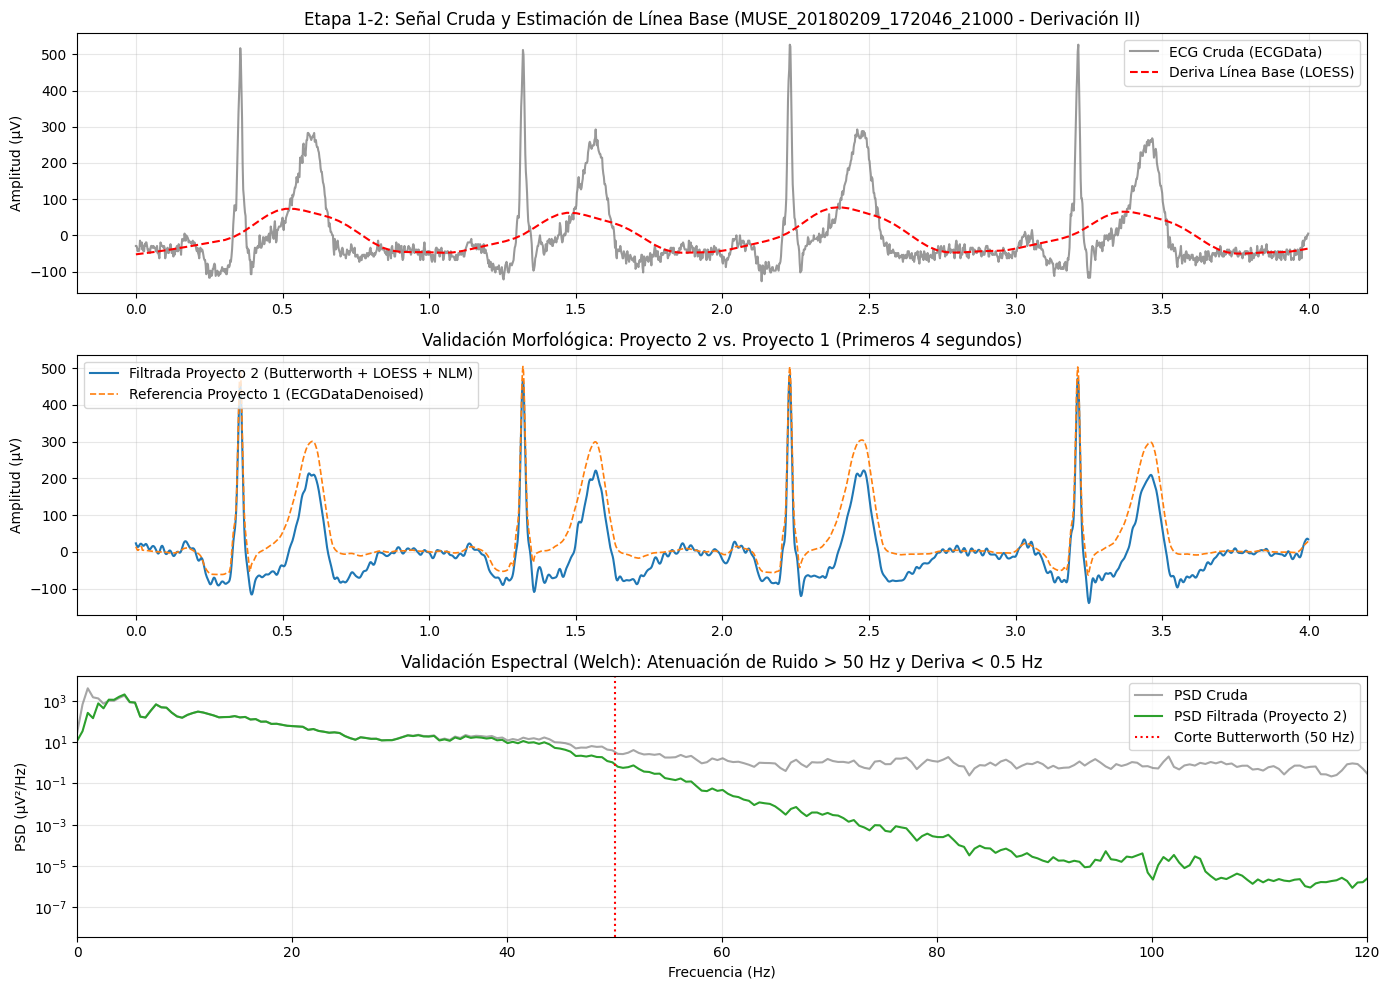

In [ ]:

# PUNTO 3: FLUJO DE FILTRADO (ZHENG ET AL., 2020) Y VALIDACIÓN VS. PROYECTO 1

# Se trabaja con todas las arritmias disponibles en la base de datos 
ARRITMIAS = ["SB", "SR", "AFIB","ST", "AF", "SA", "SVT", "AT", "AVNRT", "AVRT", "SAAWR"]

# Ruta a las señales ya filtradas usadas en el Proyecto 1 (ECGDataDenoised)
DENOISED_DIR_P1 = DATA_DIR / "ECGDataDenoised"  # Ajustar nombre de carpeta si difiere

# Se crean las funciones para trabajar con los datos de las bases de datos filtradas y sin filtrar

def cargar_derivacion_ii(ruta_csv, idx_lead=1):
    """
    Carga la derivación II (columna 1 en índice base 0) de un registro CSV.
    Maneja automáticamente si el archivo tiene o no fila de encabezados.
    """
    try:
        datos = np.loadtxt(ruta_csv, delimiter=",")
    except ValueError:
        datos = np.loadtxt(ruta_csv, delimiter=",", skiprows=1)
    return datos[:, idx_lead].astype(np.float64)


def filtro_nlm_1d(senal, half_patch=10, half_search=250, h=None):
    """
    Filtro Non-Local Means (NLM) 1D vectorizado para señales ECG.
    - half_patch: semiancho del parche de comparación (10 muestras = 20 ms a 500 Hz).
    - half_search: semiancho de la ventana de búsqueda (250 muestras = 0.5 s a 500 Hz).
    - h: parámetro de suavizado proporcional a la desviación estándar del ruido (sigma).
    """
    N = len(senal)
    # Estimación robusta del ruido (sigma) mediante MAD de las diferencias de segundo orden
    if h is None:
        diff2 = np.diff(senal, n=2)
        sigma = np.median(np.abs(diff2)) / (0.6745 * np.sqrt(6))
        h = max(1.5 * sigma, 1e-6)

    # Padding reflejado en los bordes para mantener longitud N
    pad = half_patch + half_search
    x_pad = np.pad(senal, pad_width=pad, mode="reflect")

    # Construcción de matriz de parches usando ventanas deslizantes
    patch_len = 2 * half_patch + 1
    parches = np.lib.stride_tricks.sliding_window_view(x_pad, window_shape=patch_len)
    # parches tiene forma (N + 2*half_search, patch_len)

    pesos_acum = np.zeros(N, dtype=np.float64)
    senal_acum = np.zeros(N, dtype=np.float64)
    denom = 2.0 * patch_len * (h ** 2)

    # Índices centrales correspondientes a la señal original
    idx_centro = np.arange(half_search, half_search + N)
    parches_centro = parches[idx_centro]

    # Desplazamientos dentro de la ventana de búsqueda [-half_search, +half_search]
    for shift in range(-half_search, half_search + 1):
        parches_vecinos = parches[idx_centro + shift]
        dist2 = np.sum((parches_centro - parches_vecinos) ** 2, axis=1)
        w = np.exp(-dist2 / denom)
        pesos_acum += w
        senal_acum += w * x_pad[pad + shift : pad + shift + N]

    return senal_acum / pesos_acum


def filtrar_ecg_zheng(senal_cruda, fs=500):
    """
    Implementa el flujo completo de 3 etapas de Zheng et al. (2020):
    1. Filtro Butterworth pasa-bajas (fc = 50 Hz, orden 4, fase cero).
    2. Remoción de deriva de línea base mediante regresión local LOESS (ventana 0.6 s).
    3. Suavizado Non-Local Means (NLM) para ruido residual intra-banda.
    """
    # Etapa 1: Butterworth pasa-bajas a 50 Hz, orden 4
    b, a = butter(N=4, Wn=50.0, btype="low", fs=fs)
    senal_lp = filtfilt(b, a, senal_cruda)

    # Etapa 2: Estimación y resta de línea base con LOESS (0.6 s = 300 muestras -> frac = 0.06)
    t = np.arange(len(senal_lp))
    frac_loess = 300.0 / len(senal_lp)  # 0.06 para 5000 muestras
    linea_base = lowess(senal_lp, t, frac=frac_loess, it=0, delta=15.0, return_sorted=False)
    senal_sin_base = senal_lp - linea_base

    # Etapa 3: Filtro Non-Local Means (NLM)
    senal_filtrada = filtro_nlm_1d(senal_sin_base, half_patch=10, half_search=250)
    return senal_filtrada, senal_lp, linea_base



# Comparación señal filtrada vs denoisedECG

ejemplo_id = diagnostics[diagnostics["Rhythm"] == "SR"]["FileName"].iloc[0]
ruta_cruda = SIGNALS_DIR / f"{ejemplo_id}.csv"
ecg_cruda = cargar_derivacion_ii(ruta_cruda)
ecg_p2, ecg_lp, base_est = filtrar_ecg_zheng(ecg_cruda, fs=FS)

# Comparación cuantitativa si la carpeta de Proyecto 1 (ECGDataDenoised) está disponible
ruta_p1 = DENOISED_DIR_P1 / f"{ejemplo_id}.csv"
tiene_p1 = ruta_p1.exists()

if tiene_p1:
    ecg_p1 = cargar_derivacion_ii(ruta_p1)
    rmse = np.sqrt(mean_squared_error(ecg_p1, ecg_p2))
    prd = 100.0 * np.sqrt(np.sum((ecg_p1 - ecg_p2) ** 2) / np.sum(ecg_p1 ** 2))
    corr_r = np.corrcoef(ecg_p1, ecg_p2)[0, 1]
    snr_db = 10.0 * np.log10(np.sum(ecg_p1 ** 2) / np.sum((ecg_p1 - ecg_p2) ** 2))
    print(f"Validación Registro {ejemplo_id} (Proyecto 1 vs Proyecto 2):")
    print(f"  - Correlación de Pearson (r): {corr_r:.4f}")
    print(f"  - RMSE: {rmse:.4f} µV | PRD: {prd:.2f}% | SNR: {snr_db:.2f} dB")
else:
    print(f"Registro {ejemplo_id} filtrado correctamente. (Ajusta DENOISED_DIR_P1 para métricas directas).")

# Gráfica de validación temporal y espectral 
tiempo = np.arange(len(ecg_cruda)) / FS
plt.figure(figsize=(14, 10))

# Panel 1: Señal cruda y línea base estimada por LOESS
plt.subplot(3, 1, 1)
plt.plot(tiempo[:2000], ecg_cruda[:2000], label="ECG Cruda (ECGData)", color="gray", alpha=0.8)
plt.plot(tiempo[:2000], base_est[:2000], label="Deriva Línea Base (LOESS)", color="red", linestyle="--")
plt.title(f"Etapa 1-2: Señal Cruda y Estimación de Línea Base ({ejemplo_id} - Derivación II)")
plt.ylabel("Amplitud (µV)")
plt.legend()
plt.grid(True, alpha=0.3)

# Panel 2: Comparación Señal Filtrada Proyecto 2 vs Proyecto 1
plt.subplot(3, 1, 2)
plt.plot(tiempo[:2000], ecg_p2[:2000], label="Filtrada Proyecto 2 (Butterworth + LOESS + NLM)", color="#1f77b4", lw=1.5)
if tiene_p1:
    plt.plot(tiempo[:2000], ecg_p1[:2000], label="Referencia Proyecto 1 (ECGDataDenoised)", color="#ff7f0e", linestyle="--", lw=1.2)
plt.title("Validación Morfológica: Proyecto 2 vs. Proyecto 1 (Primeros 4 segundos)")
plt.ylabel("Amplitud (µV)")
plt.legend()
plt.grid(True, alpha=0.3)

# Panel 3: Densidad Espectral de Potencia (Welch) antes y después del filtrado
f_raw, psd_raw = welch(ecg_cruda, fs=FS, nperseg=1024)
f_filt, psd_filt = welch(ecg_p2, fs=FS, nperseg=1024)
plt.subplot(3, 1, 3)
plt.semilogy(f_raw, psd_raw, label="PSD Cruda", color="gray", alpha=0.7)
plt.semilogy(f_filt, psd_filt, label="PSD Filtrada (Proyecto 2)", color="#2ca02c")
plt.axvline(50, color="red", linestyle=":", label="Corte Butterworth (50 Hz)")
plt.xlim(0, 120)
plt.title("Validación Espectral (Welch): Atenuación de Ruido > 50 Hz y Deriva < 0.5 Hz")
plt.xlabel("Frecuencia (Hz)")
plt.ylabel("PSD (µV²/Hz)")
plt.legend()
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

#### **3.1) Flujo de filtrado de Zheng et al. (2020)**

Según el artículo de la base de datos (*A 12-lead electrocardiogram database for arrhythmia research covering more than 10,000 patients*, Sci. Data, 2020), las señales de `ECGDataDenoised` se obtuvieron con tres etapas en serie:

1. **Filtro Butterworth pasa-bajas** para eliminar lo que está por encima de **50 Hz**, porque el ECG normal ocupa la banda de 0,5 a 50 Hz.
2. **Suavizador LOESS** para estimar y restar la **deriva de la línea base**.
3. **Non-Local Means (NLM)** para quitar el ruido que queda dentro de la banda.

El artículo **no reporta** el orden del filtro ni los parámetros del LOESS y del NLM. Por eso se escogieron así:

| Etapa | Parámetro | Valor | Justificación |
|---|---|---|---|
| Butterworth | Orden / corte | 4 / 50 Hz, fase cero (`filtfilt`) | La frecuencia de un ECG normal se sitúa entre 0.5 Hz y 50 Hz, por lo que este filtro elimina los componentes de señal con frecuencias superiores a 50 Hz|
| LOESS | Grado / ventana | Cuadrático / 501 muestras (1 s) | Ajusta la deriva lenta sin seguir las ondas del ECG |
| LOESS | Robustez | 5 iteraciones con pesos *bisquare* | Los QRS se tratan como valores atípicos, así la línea base sigue el nivel isoeléctrico y no "se sube" en cada latido |
| NLM | Parche / búsqueda | 21 muestras (42 ms) / ±100 muestras (±0,2 s) | El parche abarca un QRS; la búsqueda cubre segmentos parecidos cercanos |
| NLM | Suavizado h | 2·σ, con σ estimado del ruido de la señal cruda | h proporcional al ruido de cada registro |

